In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
%matplotlib inline

In [2]:
df=pd.read_csv('car_fuel_efficiency_2026.csv')
column = ['engine_displacement',
'horsepower',
'vehicle_weight',
'model_year',
'fuel_efficiency_mpg']
df = df[column]
df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

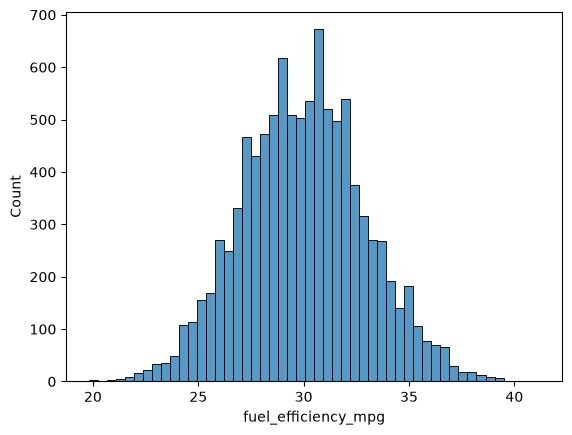

In [3]:

sns.histplot(df.fuel_efficiency_mpg, bins=50)

In [4]:
df.isnull().any().sum()

np.int64(1)

In [5]:
missing_col = df.isnull().sum()
missing_col = missing_col[missing_col > 0]
missing_col

horsepower    877
dtype: int64

In [6]:
df['horsepower'].median()

np.float64(254.0)

In [10]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]].copy().reset_index(drop = True)
df_val = df.iloc[idx[n_train:n_train  + n_val]].copy().reset_index(drop = True)
df_test = df.iloc[idx[n_train + n_val:]].copy().reset_index(drop = True)

base = ['engine_displacement',
'horsepower',
'vehicle_weight',
'model_year']
target = 'fuel_efficiency_mpg'


y_train = df_train[target].values
y_val = df_val[target].values

def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    return w[0], w[1:]

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))



In [11]:
x_train_0 = df_train[base].fillna(0).values
x_val_0 = df_val[base].fillna(0).values

w0_0, w_0 = train_linear_regression(x_train_0, y_train)
y_pred_0 = w0_0 + x_val_0.dot(w_0)
rmse_0 = rmse(y_val, y_pred_0)

In [12]:
mean = df_train['horsepower'].mean()
x_train_mean = df_train[base].fillna(mean).values
x_val_mean = df_val[base].fillna(mean).values

w0_mean, w_mean = train_linear_regression(x_train_mean, y_train)
y_pred_mean = w0_mean + x_val_mean.dot(w_mean)
rmse_mean = rmse(y_val, y_pred_mean)

In [13]:
round(rmse_0, 3)

np.float64(2.205)

In [14]:
round(rmse_mean, 3)

np.float64(2.202)

In [15]:
# VALIDATION DATA
X_train = df_train[base].fillna(0).values

def prepare_X(df):
    df_num = df[base]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(2.20529319475341)

In [18]:
#REGUALRIZED TRAINING FUNCTION
def train_linear_regression_reg(X, y, r=0.0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    reg = r * np.eye(XTX.shape[0])
    XTX = XTX + reg

    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)

    return w[0], w[1:]

def rmse(y_true, y_pred):
    error = y_pred - y_true
    mse = (error**2).mean()
    return np.sqrt(mse)

In [20]:
#TUNING THE MODEL WITH R VALUES (BEST REGULARIZATION)
X_train = prepare_X(df_train)
X_val = prepare_X(df_val)

r_list = [0, 0.01, 0.1, 1, 5, 10, 100]

for r in r_list:
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)
    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)
    print(f"r: {r:<5} -> RMSE: {round(score, 4)}")

r: 0     -> RMSE: 2.2053
r: 0.01  -> RMSE: 2.2058
r: 0.1   -> RMSE: 2.2241
r: 1     -> RMSE: 2.3492
r: 5     -> RMSE: 2.4094
r: 10    -> RMSE: 2.4195
r: 100   -> RMSE: 2.4292


In [25]:
#TUNING THE MODEL WITH SEEDS VALUES (RMSE STANDARD DEVIATION)
n = len(df)
n_val = int(0.2 * n)
n_test = int(0.2 * n)
n_train = n - (n_val + n_test)


def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    return w[0], w[1:]


def rmse(y_true, y_pred):
    error = y_pred - y_true
    mse = (error**2).mean()
    return np.sqrt(mse)


seeds = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
scores = []

for s in seeds:
    idx = np.arange(n)
    np.random.seed(s)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]].copy()
    df_val = df.iloc[idx[n_train : n_train + n_val]].copy()

    X_train = df_train[base].fillna(0).values
    X_val = df_val[base].fillna(0).values

    y_train = df_train[target].values
    y_val = df_val[target].values

    w0, w = train_linear_regression(X_train, y_train)
    y_pred = w0 + X_val.dot(w)

    score = rmse(y_val, y_pred)
    scores.append(score)

std = np.std(scores)
print(f"validation rmse: {[round(s, 4) for s in scores]}")
round(std, 3)

Validation RMSEs: [np.float64(2.2392), np.float64(2.2021), np.float64(2.1634), np.float64(2.2044), np.float64(2.2019), np.float64(2.2458), np.float64(2.2697), np.float64(2.1908), np.float64(2.2166), np.float64(2.207)]


np.float64(0.029)

In [26]:
#EVALUATION ON TEST
n = len(df)
n_val = int(0.2 * n)
n_test = int(0.2 * n)
n_train = n - (n_val + n_test)

idx = np.arange(n)
np.random.seed(9)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]].copy()
df_val = df.iloc[idx[n_train : n_train + n_val]].copy()
df_test = df.iloc[idx[n_train + n_val :]].copy()


df_full_train = pd.concat([df_train, df_val]).reset_index(drop=True)


X_full_train = df_full_train[base].fillna(0).values
y_full_train = df_full_train[target].values

X_test = df_test[base].fillna(0).values
y_test = df_test[target].values



def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    reg = r * np.eye(XTX.shape[0])
    XTX = XTX + reg

    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    return w[0], w[1:]


def rmse(y_true, y_pred):
    error = y_pred - y_true
    mse = (error**2).mean()
    return np.sqrt(mse)



w0, w = train_linear_regression_reg(X_full_train, y_full_train, r=0.001)
y_pred = w0 + X_test.dot(w)

test_rmse = rmse(y_test, y_pred)
print(f"rmse: {round(test_rmse, 3)}")

rmse: 2.236
